## Importing Environment

In [10]:
from pathlib import Path
import anndata as ad
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import scanpy as sc
import seaborn as sns
from scipy import sparse

# --- Reproducibility & style ---
RANDOM_SEED = np.random.seed(42)
sns.set_theme(style="whitegrid", context="notebook")
sc.settings.verbosity = 2

# --- Paths (works from project root or notebooks/ folder) ---
PROJECT_DIR = Path.cwd()
if PROJECT_DIR.name.lower() == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent

DATA_DIR = PROJECT_DIR / "data"
RESULTS_DIR = PROJECT_DIR / "results"
DATA_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

RAW_DATA_PATH = DATA_DIR / "pbmc3k_raw.h5ad"
PROCESSED_DATA_PATH = DATA_DIR / "pbmc3k_processed.h5ad"

## Loading Datasets

In [2]:
# Load PBMC3k: use local copy if present, otherwise download and save
if RAW_DATA_PATH.exists():
    adata = sc.read_h5ad(RAW_DATA_PATH)
else:
    adata = sc.datasets.pbmc3k()
    adata.write_h5ad(RAW_DATA_PATH, compression="gzip")

print(f"Loaded: {adata.n_obs:,} cells × {adata.n_vars:,} genes")

C:\Users\haris\AppData\Local\Temp\ipykernel_8864\3333945447.py:3: FutureWarning: Import from `scanpy.io` instead
  adata = sc.read_h5ad(RAW_DATA_PATH)


Loaded: 2,700 cells × 32,738 genes


## Viewing Dataset

In [3]:
print("AnnData dimensions (cells, genes):", adata.shape)
print("Cell metadata columns:", list(adata.obs.columns))
print("Gene metadata columns:", list(adata.var.columns))
display(adata.obs.head())
display(adata.var.head())

AnnData dimensions (cells, genes): (2700, 32738)
Cell metadata columns: []
Gene metadata columns: ['gene_ids']


""
index
AAACATACAACCAC-1
AAACATTGAGCTAC-1
AAACATTGATCAGC-1
AAACCGTGCTTCCG-1
AAACCGTGTATGCG-1


,gene_ids
index,
MIR1302-10,ENSG00000243485
FAM138A,ENSG00000237613
OR4F5,ENSG00000186092
RP11-34P13.7,ENSG00000238009
RP11-34P13.8,ENSG00000239945


## Quality Control

In [4]:
initial_cells, initial_genes = adata.n_obs, adata.n_vars
adata.var["mt"] = adata.var_names.str.upper().str.startswith("MT-")
sc.pp.calculate_qc_metrics(
    adata,
    qc_vars=["mt"],
    percent_top=None,
    log1p=False,
    inplace=True,
)
qc_columns = ["n_genes_by_counts", "total_counts", "pct_counts_mt"]
display(adata.obs[qc_columns].describe().round(2))

C:\Users\haris\AppData\Local\Temp\ipykernel_8864\3596114583.py:3: FutureWarning: The argument inplace is deprecated and will be removed in the future. Use `out=False` instead of `inplace=True`.
  sc.pp.calculate_qc_metrics(


,n_genes_by_counts,total_counts,pct_counts_mt
count,2700.00,2700.00,2700.00
mean,846.99,2366.90,2.22
std,282.10,1094.26,1.17
min,212.00,548.00,0.00
25%,690.00,1757.75,1.54
50%,817.00,2197.00,2.03
75%,953.25,2763.00,2.64
max,3422.00,15844.00,22.57


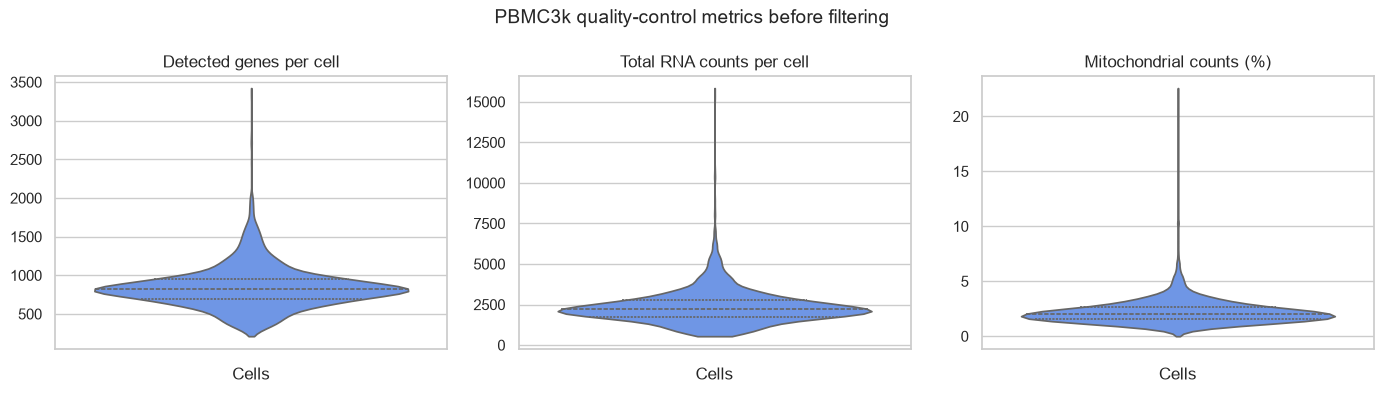

Saved results/01_quality_control.png


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
qc_titles = ["Detected genes per cell", "Total RNA counts per cell", "Mitochondrial counts (%)"]
for ax, column, title in zip(axes, qc_columns, qc_titles):
    sns.violinplot(y=adata.obs[column], ax=ax, color="#5B8FF9", inner="quartile", cut=0)
    ax.set_title(title)
    ax.set_xlabel("Cells")
    ax.set_ylabel("")
fig.suptitle("PBMC3k quality-control metrics before filtering", fontsize=14)
fig.tight_layout()
fig.savefig(RESULTS_DIR / "01_quality_control.png", dpi=220, bbox_inches="tight")
plt.show()
plt.close(fig)
print("Saved results/01_quality_control.png")

In [6]:
# Filter: keep cells with 200–2500 genes and <5% mitochondrial reads
keep = (
    adata.obs["n_genes_by_counts"].between(200, 2500) 
    & (adata.obs["pct_counts_mt"] < 5)
)
adata = adata[keep].copy()

print(f"Kept {adata.n_obs:,} / {initial_cells:,} cells ({adata.n_obs / initial_cells:.1%})")
print(f"Genes: {adata.n_vars:,}")

Kept 2,638 / 2,700 cells (97.7%)
Genes: 32,738


## Normalizing & Selecting Highly Variable Genes

In [7]:
# 1. Normalize and log-transform
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
adata.raw = adata.copy()  # Backup all genes for later plotting

# 2. Find highly variable genes (HVGs)
sc.pp.highly_variable_genes(adata, min_mean=0.0125, max_mean=3, min_disp=0.5)

n_hvg = int(adata.var["highly_variable"].sum())
print(f"HVGs: {n_hvg:,} / {adata.n_vars:,}")
if n_hvg < 2:
    raise ValueError("Too few HVGs for PCA.")

normalizing counts per cell
    finished (0:00:13)
extracting highly variable genes
    finished (0:00:06)
HVGs: 2,013 / 32,738


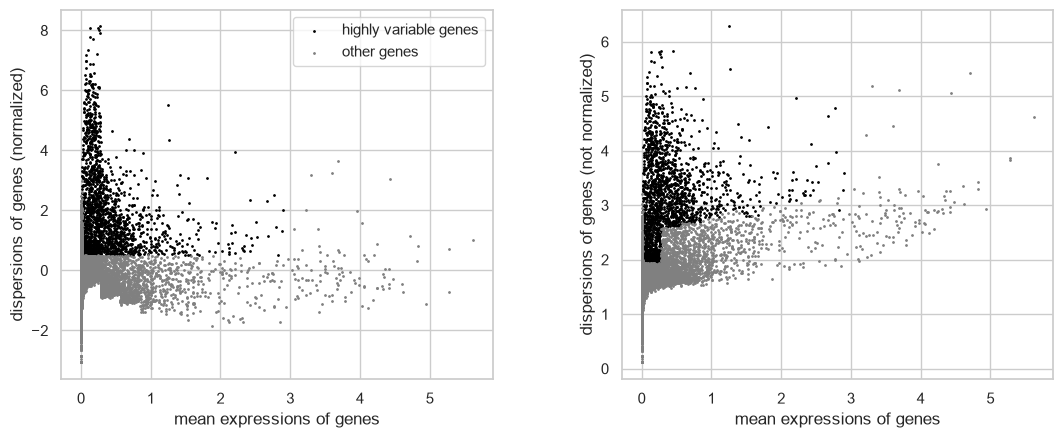

Saved results/02_highly_variable_genes.png


In [8]:
sc.pl.highly_variable_genes(adata, show=False)
fig = plt.gcf()
fig.savefig(RESULTS_DIR / "02_highly_variable_genes.png", dpi=220, bbox_inches="tight")
plt.show()
plt.close(fig)
print("Saved results/02_highly_variable_genes.png")

## PCA (principal component analysis)


In [11]:
adata = adata[:, adata.var["highly_variable"]].copy()
sc.pp.scale(adata, max_value=10)
n_pcs = min(40, adata.n_obs - 1, adata.n_vars - 1)
if n_pcs < 2:
    raise ValueError("Not enough cells or genes remain for PCA.")
sc.tl.pca(adata, n_comps=n_pcs, svd_solver="arpack", random_state=RANDOM_SEED)
print("PCA coordinates:", adata.obsm["X_pca"].shape)
print("PCA variance explained by first two components:",
      np.round(adata.uns["pca"]["variance_ratio"][:2], 4))

computing PCA
    with n_comps=40
    finished (0:00:10)
PCA coordinates: (2638, 40)
PCA variance explained by first two components: [0.0206 0.0112]


## Build the cell-cell nearest-neighbor graph

In [12]:
sc.pp.neighbors(
    adata,
    n_neighbors=10,
    n_pcs=min(40, adata.obsm["X_pca"].shape[1]),
    random_state=RANDOM_SEED,
)
connectivities = adata.obsp["connectivities"]
print(f"Neighbor graph shape: {connectivities.shape}")
print(f"Nonzero weighted connections (including both directions): {connectivities.nnz:,}")

computing neighbors
    using 'X_pca' with n_pcs = 40
    finished (0:00:19)
Neighbor graph shape: (2638, 2638)
Nonzero weighted connections (including both directions): 41,698


## Leiden clustering

In [13]:
sc.tl.leiden(
    adata,
    resolution=0.5,
    random_state=RANDOM_SEED,
    flavor="leidenalg",
    key_added="leiden",
)
cluster_sizes = adata.obs["leiden"].value_counts().sort_index()
print(f"Number of Leiden clusters: {adata.obs['leiden'].nunique()}")
display(cluster_sizes.rename("cells").to_frame())

C:\Users\haris\AppData\Local\Temp\ipykernel_8864\2839395028.py:1: FutureWarning: The argument key_added is deprecated and will be removed in the future. Use `out` instead.
  sc.tl.leiden(
C:\Users\haris\anaconda3\Lib\site-packages\scverse_misc\_deprecated\__init__.py:117: UserWarning: The `igraph` and `networkit` implementations of leiden clustering are *orders of magnitude faster*. Set the flavor argument to (and install if needed) 'igraph' or 'networkit' to use them.
  return func(*args, **kwargs)


running Leiden clustering
    finished (0:00:00)
Number of Leiden clusters: 6


,cells
leiden,
0,1189
1,640
2,419
3,341
4,36
5,13


## UMAP visualizations

UMAP creates a nonlinear 2D embedding intended to preserve local neighborhood structure.

computing UMAP
    finished (0:00:06)


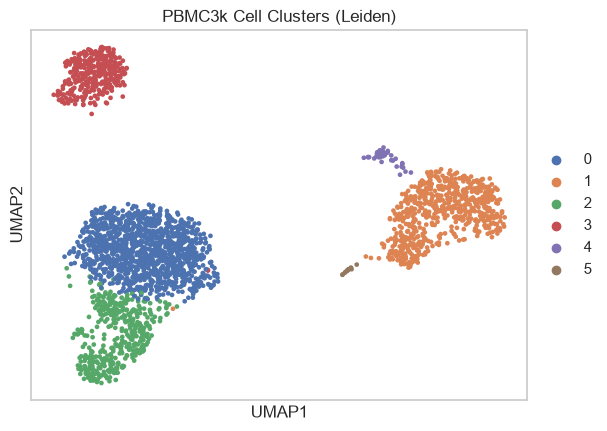

Saved results/03_umap_leiden_clusters.png


In [15]:
# 1. Calculate the 2D UMAP coordinates
sc.tl.umap(adata, random_state=RANDOM_SEED)

# 2. Draw the plot, colored by your Leiden clusters
sc.pl.umap(
    adata, 
    color="leiden", 
    title="PBMC3k Cell Clusters (Leiden)",
    show=False
)

# 3. Save and display it
fig = plt.gcf()
fig.savefig(RESULTS_DIR / "03_umap_leiden_clusters.png", dpi=220, bbox_inches="tight")
plt.show()
plt.close(fig)
print("Saved results/03_umap_leiden_clusters.png")